In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
project_path = "/content/drive/MyDrive/Saama/patient-dropout-event-forecasting/patient-dropout-event-forecasting"

In [ ]:
import pandas as pd

X_train = pd.read_csv(f"{project_path}/Phase2/train_x.csv")
y_train = pd.read_csv(f"{project_path}/Phase2/train_y.csv")

X_test = pd.read_csv(f"{project_path}/Phase2/test_x.csv")
y_test = pd.read_csv(f"{project_path}/Phase2/test_y.csv")

In [ ]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

X_train shape: (12608, 61)
y_train shape: (12608, 3)
X_test shape : (3162, 61)
y_test shape : (3162, 3)


In [ ]:
X_train.head()

,Unnamed: 0,Active Comparator Arm Number,Behavioral intervention Number,Biological intervention Number,Combination Product intervention Number,Device intervention Number,Diagnostic Test intervention Number,Dietary Supplement intervention Number,Drug intervention Number,Experimental Arm Number,...,smiless,sponsors/lead_sponsor/agency_class,study_design_info/allocation,study_design_info/intervention_model,study_design_info/intervention_model_description,study_design_info/masking,study_design_info/masking_description,study_design_info/masking_num,study_design_info/primary_purpose,study_type
0,NCT00566540,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,...,['[H][N]([H])([H])[Pt](Cl)(Cl)[N]([H])([H])[H]...,Other,NaN,Single Group Assignment,NaN,None (Open Label),NaN,0.0,Treatment,Interventional
1,NCT05451329,2.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,...,NaN,Industry,Randomized,Parallel Assignment,"Double-masked, randomized, parallel","Quadruple (Participant, Care Provider, Investi...",Quadruple masking,4.0,Treatment,Interventional
2,NCT01707381,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,...,['[H][C@](O)(CNC(C)(C)C)COC1=NSN=C1N1CCOCC1'],Industry,Randomized,Crossover Assignment,NaN,None (Open Label),NaN,0.0,Treatment,Interventional
3,NCT02854605,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,...,NaN,Industry,Randomized,Parallel Assignment,NaN,"Double (Participant, Investigator)",NaN,2.0,Treatment,Interventional
4,NCT00689052,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,...,['CCCN[C@H]1CCC2=C(C1)SC(N)=N2'],Industry,Randomized,Parallel Assignment,NaN,"Quadruple (Participant, Care Provider, Investi...",NaN,4.0,Treatment,Interventional


In [ ]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12608 entries, 0 to 12607
Data columns (total 61 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   Unnamed: 0                                        12608 non-null  object 
 1   Active Comparator Arm Number                      12508 non-null  float64
 2   Behavioral intervention Number                    12608 non-null  float64
 3   Biological intervention Number                    12608 non-null  float64
 4   Combination Product intervention Number           12608 non-null  float64
 5   Device intervention Number                        12608 non-null  float64
 6   Diagnostic Test intervention Number               12608 non-null  float64
 7   Dietary Supplement intervention Number            12608 non-null  float64
 8   Drug intervention Number                          12608 non-null  float64
 9   Experimental Arm 

In [ ]:
X_train.describe()

,Active Comparator Arm Number,Behavioral intervention Number,Biological intervention Number,Combination Product intervention Number,Device intervention Number,Diagnostic Test intervention Number,Dietary Supplement intervention Number,Drug intervention Number,Experimental Arm Number,Genetic intervention Number,...,Radiation intervention Number,Sham Comparator Arm Number,enrollment,ipd_info_type-Analytic Code,ipd_info_type-Clinical Study Report (CSR),ipd_info_type-Informed Consent Form (ICF),ipd_info_type-Statistical Analysis Plan (SAP),ipd_info_type-Study Protocol,number_of_arms,study_design_info/masking_num
count,12508.000000,12608.000000,12608.000000,12608.000000,12608.000000,12608.000000,12608.000000,12608.000000,12508.000000,12608.000000,...,12608.000000,12508.000000,12608.000000,617.000000,617.000000,617.000000,617.000000,617.000000,12508.000000,12581.000000
mean,0.289255,0.023319,0.227792,0.005155,0.031647,0.002855,0.014435,1.935676,1.546610,0.009201,...,0.045923,0.007515,108.125872,0.068071,0.633712,0.408428,0.909238,0.978930,2.236649,1.248231
std,0.662867,0.204096,0.691699,0.097019,0.217497,0.077590,0.168366,1.607294,1.493886,0.152433,...,0.239047,0.088199,227.959453,0.252073,0.482181,0.491942,0.287503,0.143733,1.682467,1.584498
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,21.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000,0.000000,...,0.000000,0.000000,49.000000,0.000000,1.000000,0.000000,1.000000,1.000000,2.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,...,0.000000,0.000000,117.000000,0.000000,1.000000,1.000000,1.000000,1.000000,3.000000,3.000000
max,8.000000,5.000000,13.000000,5.000000,4.000000,3.000000,6.000000,35.000000,24.000000,6.000000,...,5.000000,2.000000,8727.000000,1.000000,1.000000,1.000000,1.000000,1.000000,24.000000,4.000000


In [ ]:
y_train.head()

,Unnamed: 0,droupout_rate,Y/N
0,NCT00566540,0.000000,0
1,NCT05451329,0.073529,1
2,NCT01707381,0.000000,0
3,NCT02854605,0.100000,1
4,NCT00689052,1.000000,1


In [ ]:
print(y_train.columns)

Index(['Unnamed: 0', 'droupout_rate', 'Y/N'], dtype='object')


In [ ]:
y_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12608 entries, 0 to 12607
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     12608 non-null  object 
 1   droupout_rate  12608 non-null  float64
 2   Y/N            12608 non-null  int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 295.6+ KB


In [ ]:
missing = X_train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing

,0
study_design_info/masking_description,12160
ipd_info_type-Informed Consent Form (ICF),11991
ipd_info_type-Study Protocol,11991
ipd_info_type-Statistical Analysis Plan (SAP),11991
ipd_info_type-Clinical Study Report (CSR),11991
ipd_info_type-Analytic Code,11991
study_design_info/intervention_model_description,11954
oversight_info/is_fda_regulated_device,8678
oversight_info/is_fda_regulated_drug,8659
patient_data/sharing_ipd,8442


In [ ]:
missing_percentage = (X_train.isnull().sum() / len(X_train)) * 100

missing_percentage = (
    missing_percentage[missing_percentage > 0]
    .sort_values(ascending=False)
)

missing_percentage

,0
study_design_info/masking_description,96.446701
ipd_info_type-Informed Consent Form (ICF),95.106282
ipd_info_type-Study Protocol,95.106282
ipd_info_type-Statistical Analysis Plan (SAP),95.106282
ipd_info_type-Clinical Study Report (CSR),95.106282
ipd_info_type-Analytic Code,95.106282
study_design_info/intervention_model_description,94.812817
oversight_info/is_fda_regulated_device,68.829315
oversight_info/is_fda_regulated_drug,68.678617
patient_data/sharing_ipd,66.957487


In [ ]:
X_train.dtypes.value_counts()

,count
object,32
float64,29


In [ ]:
X_train.duplicated().sum()

np.int64(0)

In [ ]:
print(y_train.columns)

Index(['Unnamed: 0', 'droupout_rate', 'Y/N'], dtype='object')


In [ ]:
y_train.loc[:, "droupout_rate"].describe()

,droupout_rate
count,12608.000000
mean,0.257366
std,0.326500
min,0.000000
25%,0.017686
50%,0.111111
75%,0.348837
max,1.000000


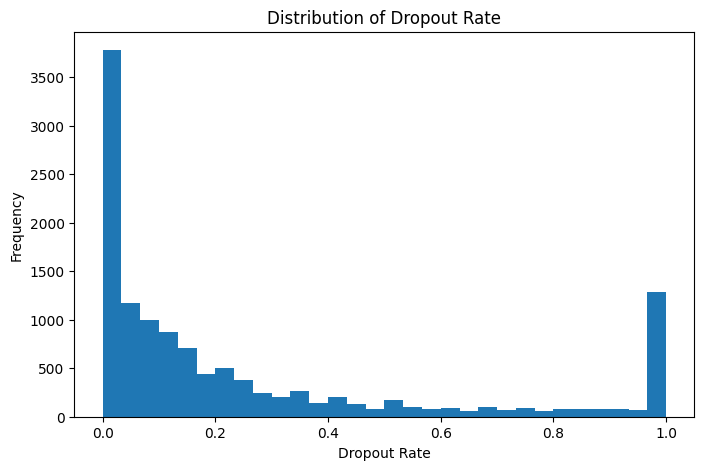

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(y_train.loc[:, "droupout_rate"], bins=30)

plt.xlabel("Dropout Rate")
plt.ylabel("Frequency")
plt.title("Distribution of Dropout Rate")

plt.show()